In [4]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Best k (by silhouette): 2
Best silhouette score: 0.017


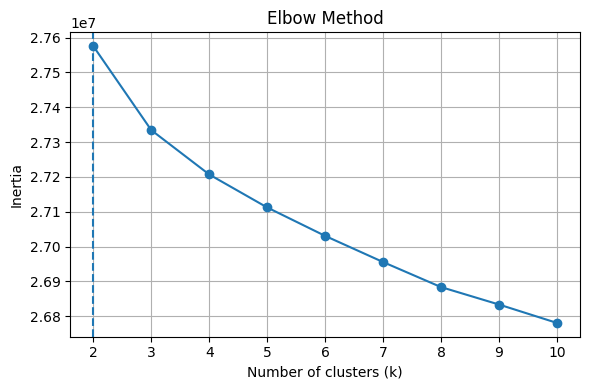

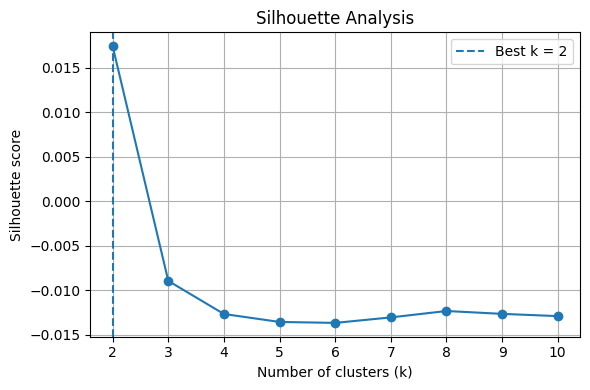

In [1]:
# ===============================
# 小鼠 TAD strength 聚类分析
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# -------------------------------
# 读取 TAD strength 矩阵
# -------------------------------
tad_strength = pd.read_csv(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/TADstrength/individual_files/mouse_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)

# -------------------------------
# 读取时间信息（可用于后续分析）
# -------------------------------
time_df = pd.read_csv(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/TADstrength/individual_files/mouse_time_sort.txt",
    sep="\t", header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))

# -------------------------------
# 行过滤：至少 15 个细胞中 TAD strength > 0
# -------------------------------
tad_strength = tad_strength[tad_strength.gt(0).sum(axis=1) >= 15]

# 转为 numpy 矩阵
data = tad_strength.values

# -------------------------------
# KMeans 聚类数评估
# -------------------------------
K_range = range(2, 11)
inertia = []
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init='auto'
    ).fit(data)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(data, kmeans.labels_)
    )

# -------------------------------
# 自动选择最佳 k（silhouette 最大）
# -------------------------------
best_k = K_range[np.argmax(silhouette_scores)]
best_score = max(silhouette_scores)

print(f"Best k (by silhouette): {best_k}")
print(f"Best silhouette score: {best_score:.3f}")

# -------------------------------
# 手肘法绘图
# -------------------------------
plt.figure(figsize=(6, 4))
plt.plot(K_range, inertia, 'o-')
plt.axvline(best_k, linestyle='--')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# 轮廓系数绘图
# -------------------------------
plt.figure(figsize=(6, 4))
plt.plot(K_range, silhouette_scores, 'o-')
plt.axvline(best_k, linestyle='--', label=f'Best k = {best_k}')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Analysis')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Cluster ID files saved.


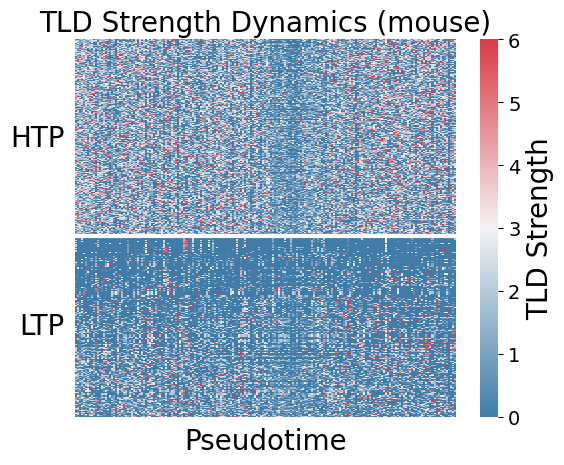

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from scipy.signal import savgol_filter
from IPython.display import SVG, display

# =============================
# 全局绘图参数
# =============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20
})

# =============================
# 读取数据
# =============================
tad_strength = pd.read_csv(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/TADstrength/individual_files/mouse_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)

time_df = pd.read_csv(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/TADstrength/individual_files/mouse_time_sort.txt",
    sep="\t", header=None, names=["sample", "time"]
)

sample_to_time = dict(zip(time_df["sample"], time_df["time"]))

# =============================
# 预处理
# =============================
# 去掉异常时间点
samples_to_remove = [s for s, t in sample_to_time.items() if 12.2 <= t <= 13.8]
tad_strength = tad_strength.drop(columns=samples_to_remove, errors='ignore')

# 保留有效信号（>=15个非0）
tad_strength = tad_strength[tad_strength.gt(0).sum(axis=1) >= 15]

# =============================
# KMeans 聚类（2类）
# =============================
kmeans = KMeans(n_clusters=2, random_state=99, n_init='auto')
tad_strength['cluster'] = kmeans.fit_predict(tad_strength)

# =============================
# 按平均强度重新定义 cluster（保证生物学意义）
# =============================
cluster_mean_strength = (
    tad_strength
    .drop(columns='cluster')
    .groupby(tad_strength['cluster'])
    .mean()
    .mean(axis=1)
)

# 高 → 低 排序
sorted_clusters = cluster_mean_strength.sort_values(ascending=False).index.tolist()

# 重新编号：高强度 = 0
cluster_remap = {old: new for new, old in enumerate(sorted_clusters)}
tad_strength['cluster'] = tad_strength['cluster'].map(cluster_remap)

# =============================
# cluster 顺序
# =============================
cluster_order = [0, 1]

# =============================
# 导出每个 cluster 的 ID
# =============================
for cid in cluster_order:
    ids = tad_strength[
        tad_strength['cluster'] == cid
    ].index
    pd.Series(ids).to_csv(
        f"mouse_cluster_{cid}_genes.txt",
        sep="\t",
        index=False,
        header=False
    )
print("Cluster ID files saved.")

# =============================
# 自动比例（推荐）
# =============================
total_display = 4538

cluster_counts = tad_strength['cluster'].value_counts(normalize=True)
cluster_ratio_map = {
    cid: cluster_counts.get(cid, 0)
    for cid in cluster_order
}

cluster_sizes = [int(total_display * cluster_ratio_map[c]) for c in cluster_order]
cluster_sizes[-1] = total_display - sum(cluster_sizes[:-1])

# =============================
# cluster 名称
# =============================
cluster_name_map = {
    0: "HTP",
    1: "LTP"
}

# =============================
# cluster 分组 & 排序
# =============================
clustered_data = []
cluster_means = []
cluster_boundaries = []
cluster_labels_pos = []

start = 0

for i, cid in enumerate(cluster_order):
    block = tad_strength[tad_strength['cluster'] == cid].drop(columns='cluster')

    # 行排序（增强结构）
    block = block.assign(row_mean=block.mean(axis=1)) \
                 .sort_values('row_mean') \
                 .drop(columns='row_mean')

    n = min(cluster_sizes[i], len(block))
    block = block.iloc[:n]

    clustered_data.append(block)

    # ===== 平滑均值曲线 =====
    mean_profile = block.mean(axis=0)

    window = min(200, len(mean_profile))
    if window % 2 == 0:
        window -= 1
    window = max(window, 3)

    smoothed = savgol_filter(mean_profile.values, window_length=window, polyorder=2)
    cluster_means.append(smoothed)

    start += n
    cluster_boundaries.append(start)
    cluster_labels_pos.append(start - n / 2)

# 合并
data_sorted = pd.concat(clustered_data)

# =============================
# 绘图（仅保留主热图）
# =============================
fig = plt.figure(figsize=(6, 5))          # 调整高度以适应单图
ax_heat = fig.add_subplot(111)

cmap = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    data_sorted,
    cmap=cmap,
    vmin=0,
    vmax=6,
    yticklabels=False,
    xticklabels=False,
    cbar_kws={'label': 'TLD Strength'},
    ax=ax_heat
)

# 分割线
for y in cluster_boundaries[:-1]:
    ax_heat.axhline(y=y, color='white', linewidth=3)

# 标签
for pos, cid in zip(cluster_labels_pos, cluster_order):
    ax_heat.text(
        x=-5,
        y=pos,
        s=cluster_name_map[cid],
        va='center',
        ha='right',
        fontsize=20
    )

ax_heat.set_ylabel("")
ax_heat.set_xlabel("Pseudotime", fontsize=20)
ax_heat.set_title("TLD Strength Dynamics (mouse)", fontsize=20)

# 颜色条字体大小
cbar = ax_heat.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)

# =============================
# 保存
# =============================
plt.tight_layout()
plt.savefig(
    "mouse_TLD_heatmap_2clusters.png",
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

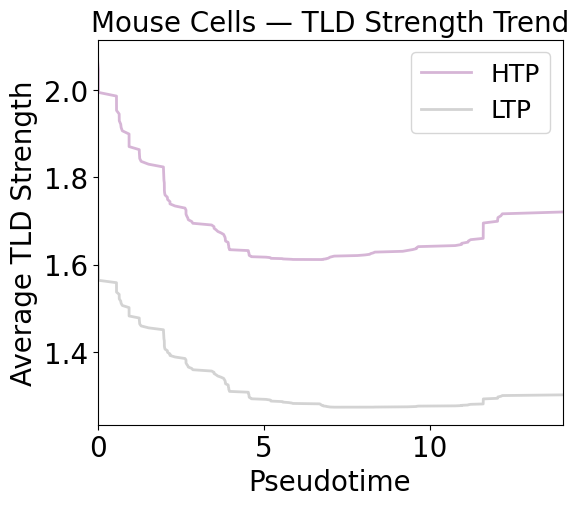

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.signal import savgol_filter

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ------------------------- 读取时间信息 -------------------------
time_df = pd.read_csv(
    '/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/TADstrength/individual_files/mouse_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))

# ------------------------- 参数 -------------------------
optimal_k = 2
smooth_window = 200

fig, ax = plt.subplots(figsize=(6, 5))

# ---------- 颜色映射：按标签固定颜色 ----------
label_colors = {
    'HTP': '#d6b5d6',
    'LTP': 'lightgrey',
}
# ----------------------------------------

# ------------------------- 绘制 Global Trend -------------------------
for i in range(optimal_k):
    cluster_data = tad_strength[tad_strength['cluster']==i].drop(columns='cluster')
    mean_values = cluster_data.mean(axis=0)

    time_vals = np.array([sample_to_time[s] for s in mean_values.index if s in sample_to_time])
    values = np.array([mean_values[s] for s in mean_values.index if s in sample_to_time])

    idx = np.argsort(time_vals)
    time_sorted, values_sorted = time_vals[idx], values[idx]

    window = min(smooth_window, len(values_sorted) if len(values_sorted)%2==1 else len(values_sorted)-1)
    smoothed = savgol_filter(values_sorted, window_length=window, polyorder=2) if window>=3 else values_sorted

    r, _ = pearsonr(time_sorted, smoothed)
    label = "HTP" if i == 0 else "LTP"
    ax.plot(time_sorted, smoothed, label=label,
            color=label_colors[label], linewidth=2)

ax.set_title('Mouse Cells — TLD Strength Trend', fontsize=20)
ax.set_xlabel('Pseudotime', fontsize=20)
ax.set_ylabel('Average TLD Strength', fontsize=20)
ax.set_xlim(0, 14)
ax.legend(fontsize=18)

plt.savefig('mouse_TLDstrength_global.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
#准备DPA基因集
#工作路径 /home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/enrichment_analysis

#一、绝对值相关性 Top N
for n in 200 500 1000 1500 2000
do
    awk '{print $1, ($2<0?- $2:$2)}' ct2genes.txt \
    | sort -k2,2nr \
    | head -n $n \
    | awk '{print $1}' \
    > ct2genes_abs_top${n}.txt
done

#二、正相关 Top N（cor > 0）
for n in 200 500 1000 1500 2000
do
    awk '$2>0' ct2genes.txt \
    | sort -k2,2nr \
    | head -n $n \
    | awk '{print $1}' \
    > ct2genes_pos_top${n}.txt
done

#三、负相关 Top N
for n in 200 500 1000 1500 2000
do
    awk '$2<0' ct2genes.txt \
    | sort -k2,2n \
    | head -n $n \
    | awk '{print $1}' \
    > ct2genes_neg_top${n}.txt
done


In [ ]:
#准备背景基因集
grep -v -f mouse_cluster_0_genes.txt all_mouse_gene_id.txt | awk 'NR>1' >mouse_cluster_0_genes.non.txt
grep -v -f mouse_cluster_1_genes.txt all_mouse_gene_id.txt | awk 'NR>1' >mouse_cluster_1_genes.non.txt



[ZGA] 列联表：
                    ZGA  非 ZGA
TAD strength 升高区域  1169  17495
其他区域                935  24107
优势比 (OR) = 1.723
P 值        = 7.636e-34

[DPA] 列联表：
                   DPA  非 DPA
TAD strength 升高区域  691  17973
其他区域               644  24398
优势比 (OR) = 1.457
P 值        = 1.660e-11


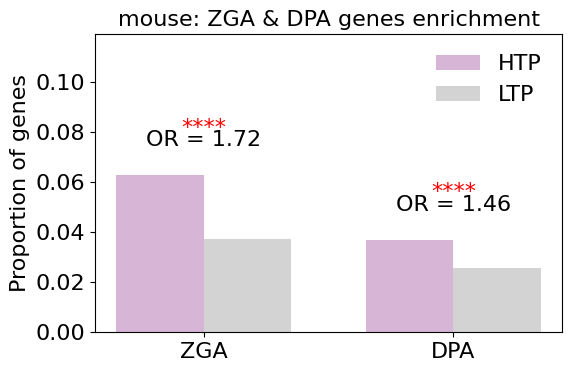

In [3]:
#mouse C0,ZGA,DPA
# =========================================================
# mouse C0：ZGA / DPA 基因在 TAD strength 随拟时序升高区域中的富集分析
# ---------------------------------------------------------
# 本脚本用于检验：
#   ZGA 基因和发育潜能相关基因（DPA）
# 是否在 TAD strength 随拟时序增加的区域（IVF C0 cluster）
# 中显著富集，相对于其他所有区域。
#
# 富集分析采用 Fisher 精确检验，
# 并通过柱状图展示目标区域与其他区域中
# ZGA / DPA 基因所占比例的差异。
# =========================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact


plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16
})

# ===============================
# 1. 基础函数
# ===============================

def read_gene_list(path):
    """
    读取基因列表文件，返回基因 ID 的集合（set）。

    假设：
    - 每行包含一个基因 ID（或第一列为基因 ID）
    - 使用 set 以保证基因唯一性，并便于集合运算
    """
    genes = []
    with open(path) as f:
        for line in f:
            if line.strip():
                genes.append(line.strip().split()[0])
    return set(genes)


def build_contingency_table(target_genes, other_genes, gene_set):
    """
    构建 Fisher 精确检验所需的 2×2 列联表：

                         gene_set    非 gene_set
    target_genes            a            b
    other_genes             c            d

    其中：
    - target_genes：位于 TAD strength 随拟时序升高区域中的基因
    - other_genes ：位于其余所有区域中的基因
    - gene_set    ：待检验的基因集合（ZGA 或 DPA）
    """
    a = len(target_genes & gene_set)
    b = len(target_genes) - a
    c = len(other_genes & gene_set)
    d = len(other_genes) - c

    table = [[a, b],
             [c, d]]
    return table


def enrichment_stats(target_genes, other_genes, gene_set):
    """
    对给定基因集合（ZGA 或 DPA）计算富集统计量，包括：

    - Fisher 精确检验的优势比（odds ratio）
    - Fisher 精确检验的 p 值
    - gene_set 在目标区域中的比例
    - gene_set 在其他区域中的比例
    """
    table = build_contingency_table(target_genes, other_genes, gene_set)
    or_value, p_value = fisher_exact(table)

    # 目标区域中 gene_set 的比例
    target_prop = table[0][0] / sum(table[0])
    # 其他区域中 gene_set 的比例
    other_prop = table[1][0] / sum(table[1])

    return table, or_value, p_value, target_prop, other_prop


# ===============================
# 2. 读取基因集合
# ===============================

# ZGA 基因列表
ZGA_genes = read_gene_list(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/enrichment_analysis/mouse_majorZGA_id.txt"
)

# DPA（发育潜能相关）基因列表
DPA_genes = read_gene_list(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/enrichment_analysis/ct2genes_pos_top2000.txt"
)

# IVF 中 TAD strength 随拟时序升高（C0 cluster）区域对应的基因
target_genes = read_gene_list(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/enrichment_analysis/mouse_cluster_0_genes.txt"
)

# IVF 中其余区域对应的基因
other_genes = read_gene_list(
    "/home/lihaoxing/mouse_embryo_schic/oocyte_1c_2c_4c/enrichment_analysis/mouse_cluster_0_genes.non.txt"
)

# 确保目标区域与其他区域的基因集合不重叠
assert len(target_genes & other_genes) == 0


# ===============================
# 3. 富集分析计算
# ===============================

# 待分析的基因集合
gene_sets = {
    "ZGA": ZGA_genes,
    "DPA": DPA_genes
}

results = {}

for label, geneset in gene_sets.items():
    table, or_value, p_value, tp, op = enrichment_stats(
        target_genes, other_genes, geneset
    )
    results[label] = {
        "table": table,
        "odds_ratio": or_value,
        "p_value": p_value,
        "target_prop": tp,
        "other_prop": op
    }

    # 打印列联表和统计结果，便于复现与审查
    print(f"\n[{label}] 列联表：")
    print(pd.DataFrame(
        table,
        index=["TAD strength 升高区域", "其他区域"],
        columns=[label, f"非 {label}"]
    ))
    print(f"优势比 (OR) = {or_value:.3f}")
    print(f"P 值        = {p_value:.3e}")


# ===============================
# 4. 绘制柱状图（对应 Fig. 3h 风格）
# ===============================

labels = list(results.keys())
target_props = [results[l]["target_prop"] for l in labels]
other_props = [results[l]["other_prop"] for l in labels]
p_values = [results[l]["p_value"] for l in labels]
or_values = [results[l]["odds_ratio"] for l in labels]

x = np.arange(len(labels))
width = 0.35


plt.figure(figsize=(6, 4))

# 目标区域（TAD strength 随拟时序升高）
plt.bar(
    x - width / 2,
    target_props,
    width,
    label="HTP",
    color="#d6b5d6"
)

# 其他区域
plt.bar(
    x + width / 2,
    other_props,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("Proportion of genes")
plt.title("mouse: ZGA & DPA genes enrichment")
plt.xticks(x, labels)
plt.ylim(0, max(target_props + other_props) * 1.9)

# 标注 p 值与显著性水平
for i, p in enumerate(p_values):
    y = max(target_props[i], other_props[i])
    #plt.text(i, y + 0.01, f"p = {p:.2e}", ha="center", va="bottom")
    plt.text(
        i,
        y + 0.01,
        f"OR = {or_values[i]:.2f}",
        ha="center",
        va="bottom",
        fontsize=16
    )

    if p <= 0.05:
        if p <= 1e-4:
            star = "****"
        elif p <= 1e-3:
            star = "***"
        elif p <= 1e-2:
            star = "**"
        else:
            star = "*"
        plt.text(i, y + 0.015, star, ha="center", va="bottom",
                 fontsize=16, color="red")

plt.legend(frameon=False)
plt.tight_layout()

# 保存为矢量格式，便于论文排版
plt.savefig(
    "mouse_TADstrength_ZGA_DPA_enrichment.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
